<a href="https://colab.research.google.com/github/aiden-zhu/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aiden Zhu, Anaya Green, Noah Weinstein

**Date:** 11/18/2026

(299, 13) 

age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000                299.000000  299.000000   
mean    60.833893    0.431438                581.839465    0.418060   
std     11.894809    0.496107                970.287881    0.494067   
min     40.000000    0.000000                 23.000000    0.000000   
25%     51.000000    0.000000                116.500000    0.000000   
50%     60.000000    0.000000                250.000000    0.000000   
75%    

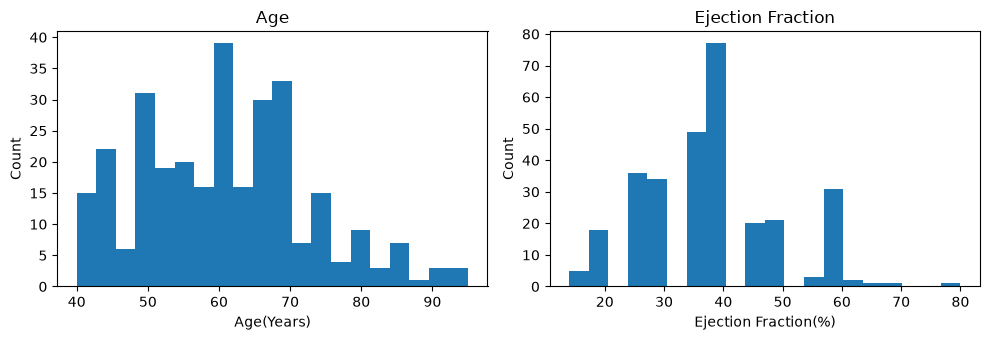

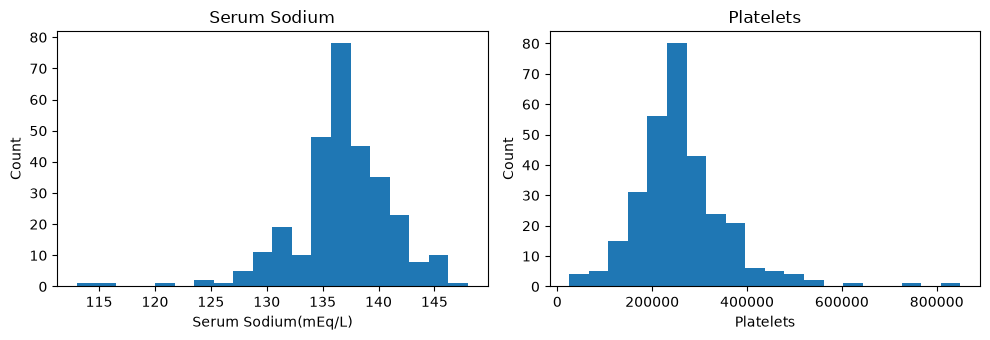

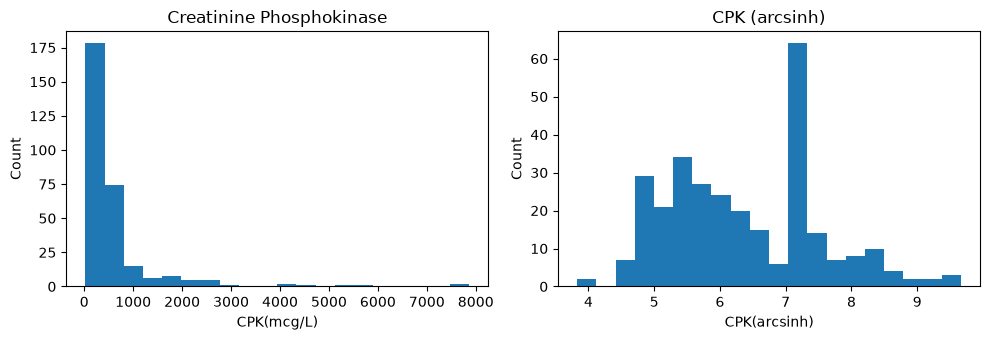

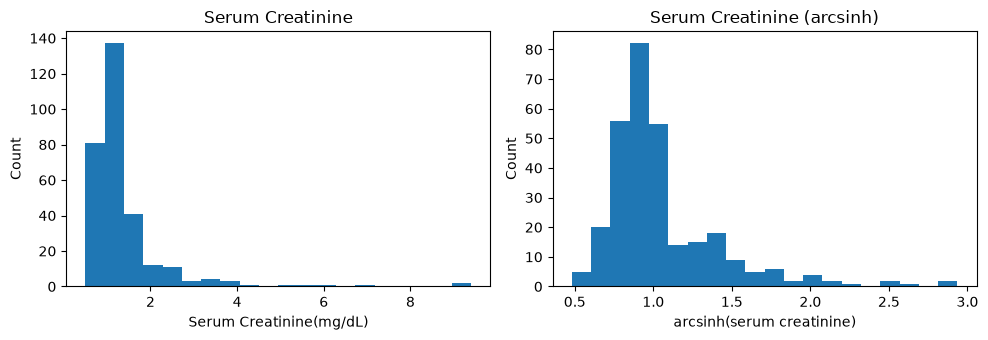

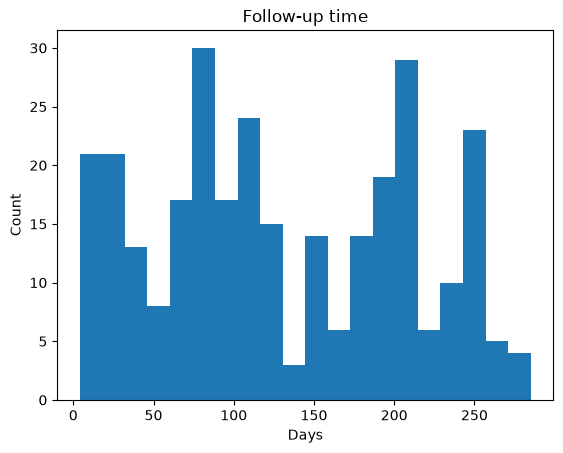

224 training patients; 75 test patients
Tree accuracy: 0.693


Predicted,0,1
Actual,,
0,45,6
1,17,7


Logistic accuracy: 0.667
Test BCE: 0.533


Predicted,0,1
Actual,,
0,43,8
1,17,7


Seed 100


Predicted,0,1
Actual,,
0,45,6
1,17,7


... (10 outputs left out)

Seed 4


Predicted,0,1
Actual,,
0,39,12
1,10,14


Predicted,0,1
Actual,,
0,43,8
1,11,13


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
100,0.0600,0.3267,0.0003,0.1363,-0.0785,0.4503,0.0,0.5989,-0.0221,-0.0529,-0.3870
1,0.0476,0.4166,0.0003,-0.2001,-0.1011,0.1682,-0.0,0.7222,-0.0050,-0.9109,0.1299
2,0.0551,0.3341,0.0003,0.2361,-0.0673,0.3566,0.0,0.7725,-0.0248,-0.4096,0.1755
3,0.0602,0.5624,0.0004,0.2617,-0.0614,0.0753,-0.0,0.6188,-0.0250,-0.3447,0.2131
4,0.0527,0.3995,0.0003,0.3307,-0.0746,0.3038,-0.0,0.8672,-0.0193,-0.7136,0.3663


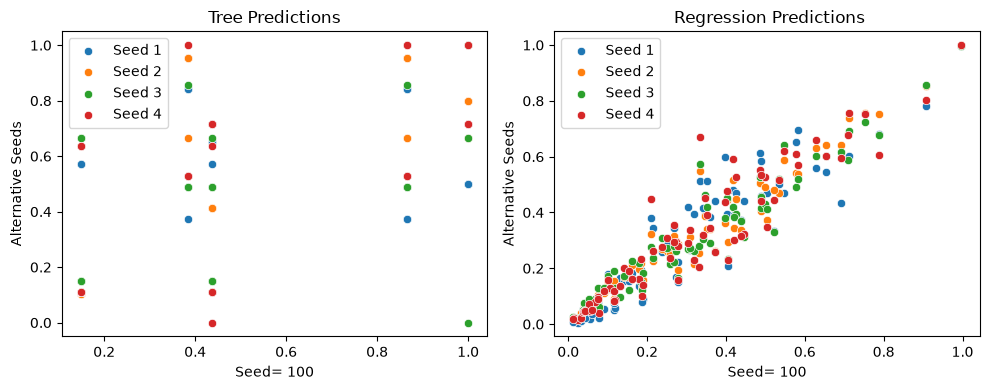

Seed: 1
Tree correlation: 0.682
Logistic correlation: 0.928

Seed: 2
Tree correlation: 0.84
Logistic correlation: 0.971

Seed: 3
Tree correlation: 0.695
Logistic correlation: 0.958

Seed: 4
Tree correlation: 0.723
Logistic correlation: 0.935

Seed: 1
Tree intercept: 0.077
Tree slope: 0.682
Tree R-squared: 0.465
Regression intercept: 0.016
Regression slope: 0.924
Regression R-squared: 0.861

Seed: 2
Tree intercept: 0.041
Tree slope: 0.864
Tree R-squared: 0.706
Regression intercept: 0.014
Regression slope: 0.937
Regression R-squared: 0.943

Seed: 3
Tree intercept: 0.064
Tree slope: 0.638
Tree R-squared: 0.483
Regression intercept: 0.023
Regression slope: 0.886
Regression R-squared: 0.917

Seed: 4
Tree intercept: 0.056
Tree slope: 0.757
Tree R-squared: 0.522
Regression intercept: 0.022
Regression slope: 0.93
Regression R-squared: 0.874



In [1]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss


#df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")

print(df.shape, "\n")
print(df.dtypes, "\n")
print(df.describe(), "\n")
print(df.isnull().sum(), "\n")
df.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["age"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Age", xlabel="Age(Years)", ylabel="Count")
df["ejection_fraction"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="Ejection Fraction", xlabel="Ejection Fraction(%)", ylabel="Count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["serum_sodium"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Serum Sodium", xlabel="Serum Sodium(mEq/L)", ylabel="Count")
df["platelets"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="Platelets", xlabel="Platelets", ylabel="Count")
plt.tight_layout()
plt.show()

df["cpk_arcsinh"] = np.arcsinh(df["creatinine_phosphokinase"])
df["creatinine_arcsinh"] = np.arcsinh(df["serum_creatinine"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["creatinine_phosphokinase"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Creatinine Phosphokinase", xlabel="CPK(mcg/L)", ylabel="Count")
df["cpk_arcsinh"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="CPK (arcsinh)", xlabel="CPK(arcsinh)", ylabel="Count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["serum_creatinine"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Serum Creatinine", xlabel="Serum Creatinine(mg/dL)", ylabel="Count")
df["creatinine_arcsinh"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="Serum Creatinine (arcsinh)", xlabel="arcsinh(serum creatinine)", ylabel="Count")
plt.tight_layout()
plt.show()

df["time"].hist(bins=20, grid=False)
plt.title("Follow-up time")
plt.xlabel("Days")
plt.ylabel("Count")
plt.show()

seed = 100

features = [
    "age", "anaemia", "creatinine_phosphokinase", "diabetes",
    "ejection_fraction", "high_blood_pressure", "platelets",
    "serum_creatinine", "serum_sodium", "sex", "smoking"
]
X = df[features]
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=seed, stratify=y
)
print(len(X_train), "training patients;", len(X_test), "test patients")

tree = DecisionTreeClassifier(max_depth=3, random_state=seed).fit(
    X_train, y_train
)
p_tree = tree.predict_proba(X_test)[:, 1]
y_hat_tree = tree.predict(X_test)
print("Tree accuracy:", round(np.sum(y_hat_tree == y_test) / len(y_test), 3))
display(pd.crosstab(y_test, y_hat_tree,
            rownames=["Actual"], colnames=["Predicted"]))

model = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-8)
model.fit(X_train, y_train);
p_test = model.predict_proba(X_test)[:, 1]
predicted = model.predict(X_test)
print("Logistic accuracy:", round(np.sum(predicted == y_test) / len(y_test), 3))
print(f"Test BCE: {log_loss(y_test, p_test):.3f}")
display(pd.crosstab(y_test, predicted,
            rownames=["Actual"], colnames=["Predicted"]))

predictions = pd.DataFrame({
    "actual": y_test,
    "tree": p_tree,
    "logistic": p_test,
})
predictions.head()

seeds = [seed, 1, 2, 3, 4]
tree_models = []
logistic_models = []

for s in seeds:
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.25, random_state=s, stratify=y
    )
    tree_s = DecisionTreeClassifier(max_depth=3, random_state=s).fit(
        X_train_s, y_train_s
    )
    model_s = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-8)
    model_s.fit(X_train_s, y_train_s);
    tree_models.append(tree_s)
    logistic_models.append(model_s)

    print(f"Seed {s}")
    display(pd.crosstab(y_test_s, tree_s.predict(X_test_s),
                rownames=["Actual"], colnames=["Predicted"]))
    display(pd.crosstab(y_test_s, model_s.predict(X_test_s),
                rownames=["Actual"], colnames=["Predicted"]))

coefficients = np.array([fit.coef_[0] for fit in logistic_models])
display(pd.DataFrame(coefficients, columns=features, index=seeds).round(4))

tree_predictions = np.array([fit.predict_proba(X_test)[:, 1] for fit in tree_models])
logistic_predictions = np.array([fit.predict_proba(X_test)[:, 1] for fit in logistic_models])




#Q4

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for i in range(1, len(seeds)):
    sns.scatterplot(
        x=tree_predictions[0],
        y=tree_predictions[i],
        ax=axes[0],
        label=f"Seed {seeds[i]}"
    )

axes[0].set(
    title="Tree Predictions",
    xlabel="Seed= 100",
    ylabel="Alternative Seeds"
)

for i in range(1, len(seeds)):
    sns.scatterplot(
        x=logistic_predictions[0],
        y=logistic_predictions[i],
        ax=axes[1],
        label=f"Seed {seeds[i]}"
    )

axes[1].set(
    title=" Regression Predictions",
    xlabel="Seed= 100",
    ylabel="Alternative Seeds"
)

plt.tight_layout()
plt.show()
for i in range(1, len(seeds)):
    tree_corr = pd.Series(tree_predictions[0]).corr(
        pd.Series(tree_predictions[i])
    )
    logistic_corr = pd.Series(logistic_predictions[0]).corr(
        pd.Series(logistic_predictions[i])
    )

    print("Seed:", seeds[i])
    print("Tree correlation:", round(tree_corr, 3))
    print("Logistic correlation:", round(logistic_corr, 3))
    print()

def slr(x, y):
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    y_hat = b0 + b1 * x
    return {
        "b0": b0,
        "b1": b1,
        "y_hat": y_hat,
        "residuals": y - y_hat
    }
for i in range(1, len(seeds)):
    tree_fit = slr(tree_predictions[0], tree_predictions[i])
    regression_fit = slr(logistic_predictions[0], logistic_predictions[i])

    tree_r2 = 1 - np.sum(tree_fit["residuals"]**2) / np.sum(
        (tree_predictions[i] - np.mean(tree_predictions[i]))**2
    )

    regression_r2 = 1 - np.sum(regression_fit["residuals"]**2) / np.sum(
        (logistic_predictions[i] - np.mean(logistic_predictions[i]))**2
    )

    print("Seed:", seeds[i])
    print("Tree intercept:", round(tree_fit["b0"], 3))
    print("Tree slope:", round(tree_fit["b1"], 3))
    print("Tree R-squared:", round(tree_r2, 3))
    print("Regression intercept:", round(regression_fit["b0"], 3))
    print("Regression slope:", round(regression_fit["b1"], 3))
    print("Regression R-squared:", round(regression_r2, 3))
    print()




Q1

The heart_failure dataset has 299 patients and 13 variables, all of which are numeric, and there are no missing values in any column. The binary variables (anaemia, diabetes, high_blood_pressure, sex, smoking, and DEATH_EVENT) are already coded as 0/1, so they didn’t need any recoding. Our outcome, DEATH_EVENT, has a mean of 0.321, meaning about 32% of patients died during follow-up. Because the classes are unbalanced, we stratified our train/test splits on DEATH_EVENT so each split keeps roughly the same share of deaths.

Looking at the histograms, age (40 to 95), ejection fraction (14 to 80), serum sodium (113 to 148), and platelets were all in reasonable clinical ranges, so we left them as they were. Creatinine phosphokinase and serum creatinine were heavily right-skewed. CPK has a median of 250 but a max of 7,861, and serum creatinine has a median of 1.1 but a max of 9.4. We created arcsinh-transformed versions of both, which pulled in the long right tails and made the distributions much more symmetric. We kept the raw versions in our models, since trees aren’t affected by transformations that keep the same order of values, and the raw units are easier to interpret.

We dropped the time variable from our features. Time is the length of each patient’s follow-up period, and that period is partly determined by the death itself, since a patient who dies early has a short follow-up. Including it would leak information about the outcome into our predictors, so a model using it would look better than it really is.

Q3

Across the five seeds (100, 1, 2, 3, 4), the trees' results varied significantly. The number of patients predicted to die ranged from 9 and 26, and accuracy ranged from 0.693 to 0.773. The logistic coefficients were more stable for non-binary features (age 0.048-0.060 and ejection fraction -0.061 to -0.101), but slightly unstable for binary features (diabetes went from -0.20 in seed 1 to positive elsewhere; high blood pressure ranged from 0.08 to 0.40). The predictions are in the code output.



Q4

a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?

**No, they do not appear to be similar. The tree predictions show more variation across the different seeds, with points scattered and clustered at certain predicted values. In comparison, the logistic regression predictions follow a more consistent positive linear pattern.**

b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?

**The tree correlations range from 0.682 to 0.840, while the regression correlations range from 0.928 to 0.971. Both models have positive correlations, but the regression predictions are much more highly correlated across the various seeds.**

c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

**The tree models have intercepts ranging from 0.041 to 0.077, slopes ranging from 0.638 to 0.864, and R-squared values ranging from 0.465 to 0.706. The intercepts are realtively close to zero, but the slopes and R-squared values are not close to 1. In comparison, the regression models have intercepts ranging from 0.012 to 0.021, slopes ranging from 0.894 to 0.945, and R-squared values ranging from 0.860 to 0.944.**

Q5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?

The linear models do. Age and Ejection Fraction stay very close together, while diabetes, high blood pressure, and anaemia very a little more. We believe that can be attributed to the fact that they are binary catgories. Against the seed-100 model, the correlation ranges between 0.92 and 0.97, and the associated r^2 values are around 86%. The points fall relatively along y=x, so the linear models appear relatively consistent. Trees don't have coefficients, but their predictions were less consistent. The correlations ranged between 0.68 and 0.84, and different seeds disagreed significantly about the same patient. This makes sense, because we know trees to be fragile because their splits are based off of their particular training samples.

Q6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

Based on our results, we believe that statement to be generally true for this dataset. Looking first at the logistic models, our coefficients varied noticeably, giving our models different appearances. Even so, the logistically modeled predictions correlated with the seed-100 model at high rates, showing that a models appearance and its predictive ability may not be directly associated. Our results with trees definitely display this statement less, since the tree predictions vary quite a bit amongst themselves. We'd still quantify their predictions to be "often very similar" in accordance with the statement, but they don't support it as well as linear models do. In general, our results from this dataset support the validity of that statement to a significant, but not wholly convincing, extent.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]